# Customer Segmentation using SOM

In [19]:
# Install if needed
# !pip install pandas numpy matplotlib seaborn scikit-learn minisom scipy

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from minisom import MiniSom
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.stats import f_oneway

# Read CSV from the same folder as the notebook
data = pd.read_csv("CC GENERAL.csv")
print(data.shape)
data.head()


(8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


## 1. Data cleaning

In [20]:
# Remove customer ID and fill missing values
customer_id = data["CUST_ID"] if "CUST_ID" in data.columns else data.index
data = data.drop(columns=["CUST_ID"], errors="ignore")
data = data.fillna(data.median(numeric_only=True))

print(data.isnull().sum().sum())
data.describe()


0


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.282473,1733.143852,844.906767,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.646702,2895.063757,2332.792322,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,170.857654,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,788.713501,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


## 2. EDA

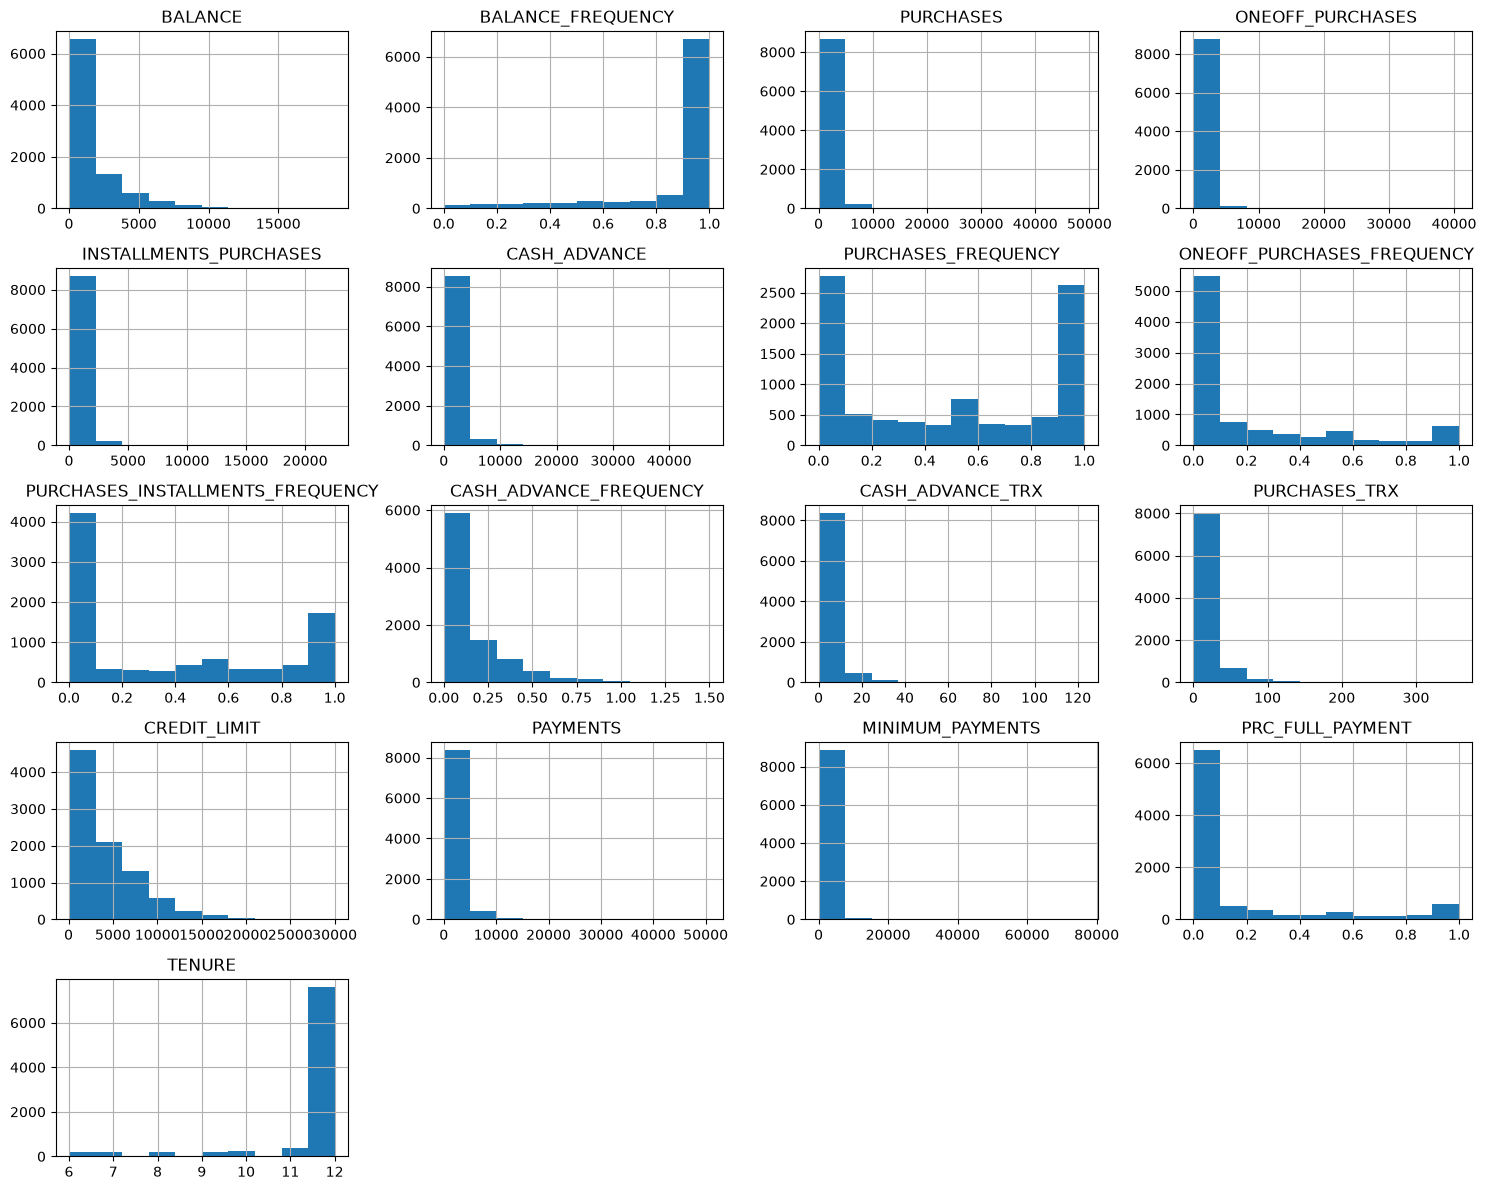

In [21]:
# Histograms
data.hist(figsize=(15, 12))
plt.tight_layout()
plt.show()

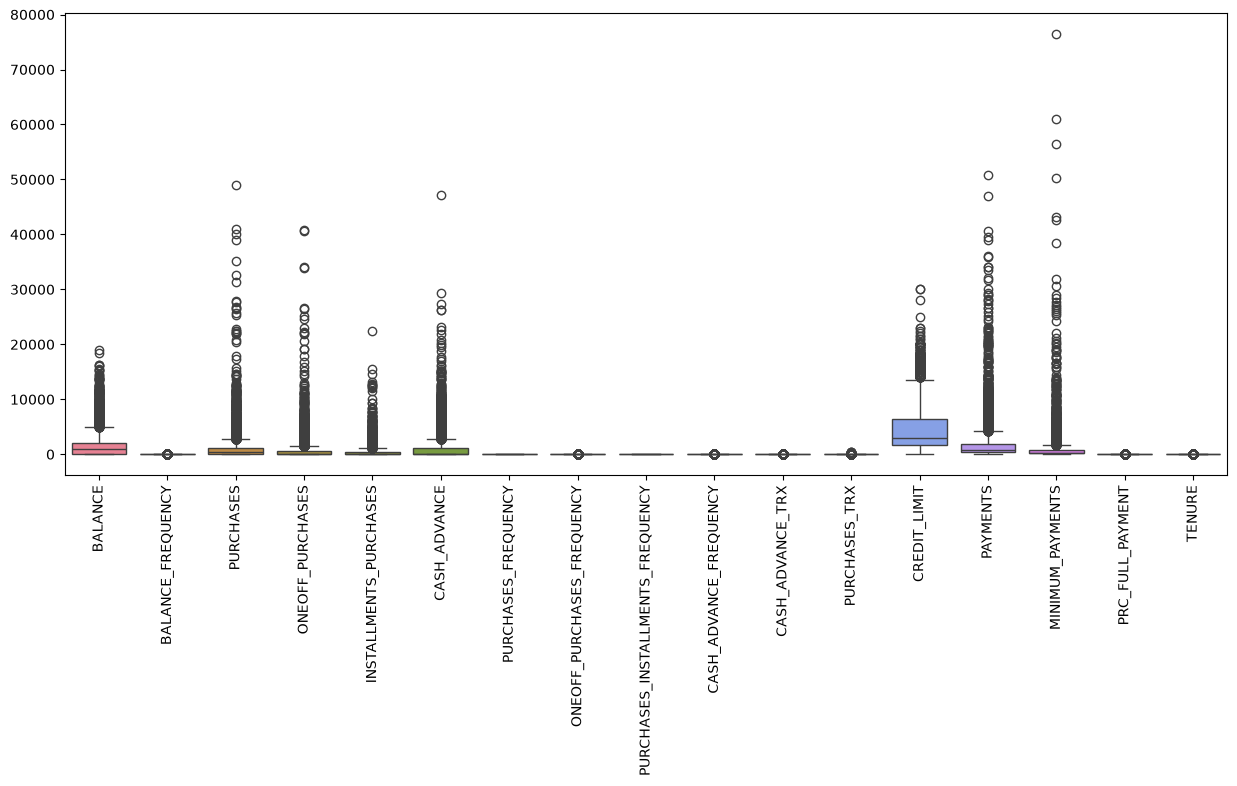

In [22]:
# Box plots
plt.figure(figsize=(15, 6))
sns.boxplot(data=data)
plt.xticks(rotation=90)
plt.show()


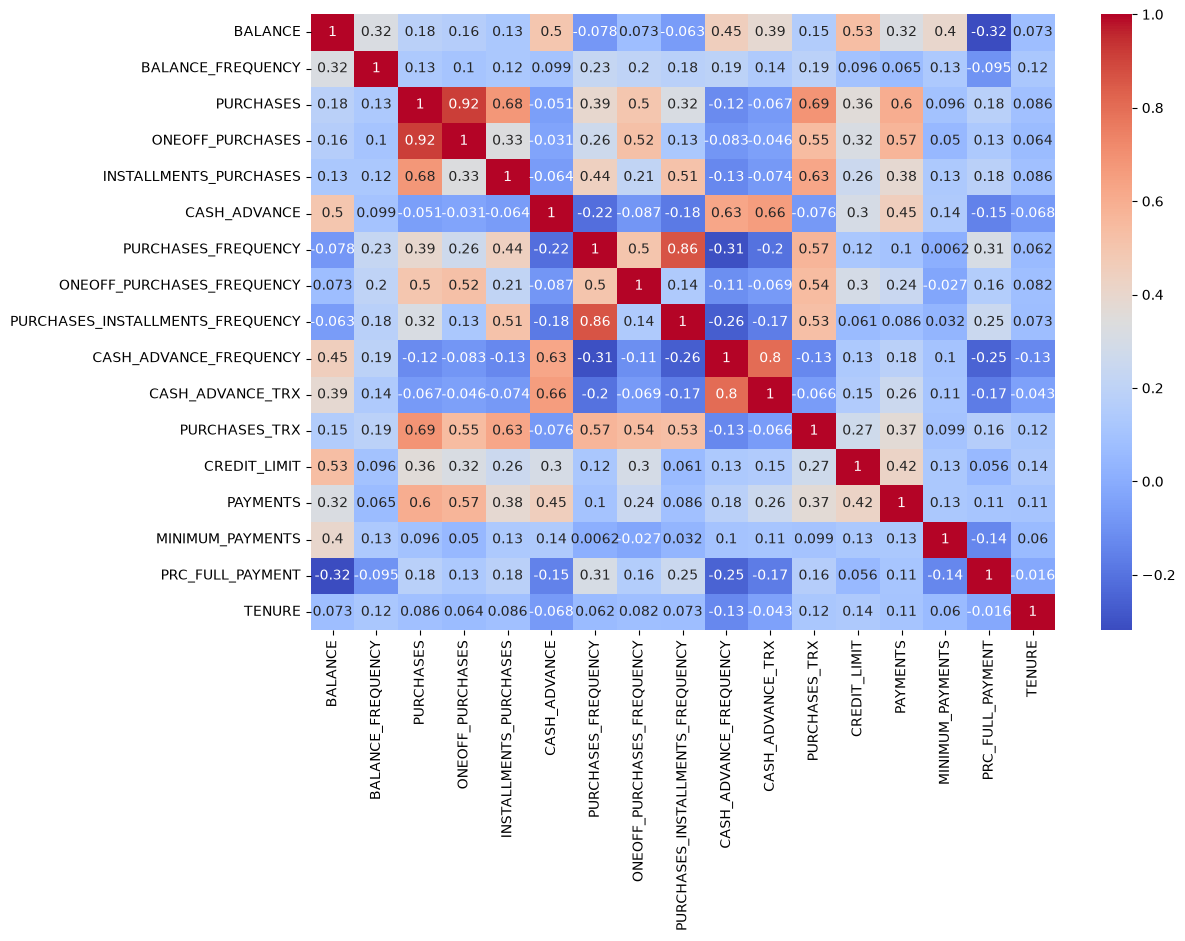

In [23]:
# Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(data.corr(), cmap="coolwarm", annot=True)
plt.show()


In [24]:
# Find outliers using IQR
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1
outliers = ((data < Q1 - 1.5 * IQR) | (data > Q3 + 1.5 * IQR))
outliers.sum()


BALANCE                              695
BALANCE_FREQUENCY                   1493
PURCHASES                            808
ONEOFF_PURCHASES                    1013
INSTALLMENTS_PURCHASES               867
CASH_ADVANCE                        1030
PURCHASES_FREQUENCY                    0
ONEOFF_PURCHASES_FREQUENCY           782
PURCHASES_INSTALLMENTS_FREQUENCY       0
CASH_ADVANCE_FREQUENCY               525
CASH_ADVANCE_TRX                     804
PURCHASES_TRX                        766
CREDIT_LIMIT                         248
PAYMENTS                             808
MINIMUM_PAYMENTS                     909
PRC_FULL_PAYMENT                    1474
TENURE                              1366
dtype: int64

## 3. Scaling and PCA

Min-Max range: 0.0 1.0000000000000002
Standard mean: 3.5934534122533735e-17
Standard deviation: 1.0


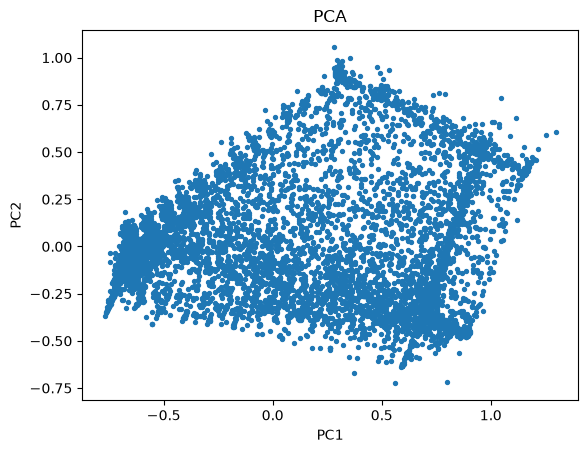

PCA variance: [0.49460243 0.14008008]


In [25]:
# Create ratio features
if "PURCHASES" in data.columns and "CREDIT_LIMIT" in data.columns:
    data["PURCHASES_RATIO"] = data["PURCHASES"] / (data["CREDIT_LIMIT"] + 1e-9)

if "PAYMENTS" in data.columns and "MINIMUM_PAYMENTS" in data.columns:
    data["PAYMENTS_RATIO"] = data["PAYMENTS"] / (data["MINIMUM_PAYMENTS"] + 1e-9)

data = data.replace([np.inf, -np.inf], np.nan)
data = data.fillna(data.median(numeric_only=True))

# Compare Min-Max and Standard scaling
X_minmax = MinMaxScaler().fit_transform(data)
X_standard = StandardScaler().fit_transform(data)

print("Min-Max range:", X_minmax.min(), X_minmax.max())
print("Standard mean:", X_standard.mean())
print("Standard deviation:", X_standard.std())

# Use Min-Max scaled data for SOM
X = X_minmax

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.scatter(X_pca[:, 0], X_pca[:, 1], s=8)
plt.title("PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

print("PCA variance:", pca.explained_variance_ratio_)


## 4. Train SOM

In [26]:
# Create and train SOM
som = MiniSom(10, 10, X.shape[1], sigma=3, learning_rate=0.5,
              neighborhood_function="gaussian", random_seed=42)

som.random_weights_init(X)
som.train_random(X, 10000)

print("Quantization error:", som.quantization_error(X))
print("Topographic error:", som.topographic_error(X))

# Save trained model and weights in the same folder
with open("som_trained_model.pkl", "wb") as f:
    pickle.dump(som, f)

np.save("som_weights.npy", som.get_weights())
print("Model saved.")


Quantization error: 0.2842200136142991
Topographic error: 0.027932960893854747
Model saved.


## 5. SOM visualizations

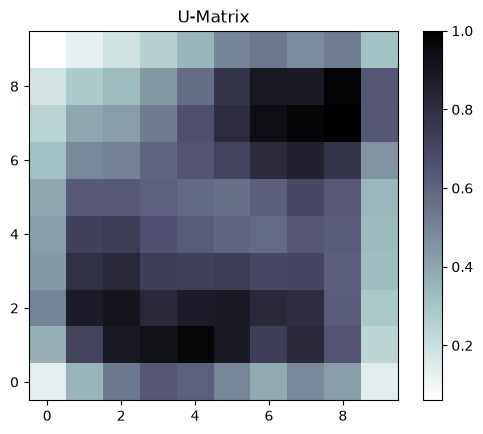

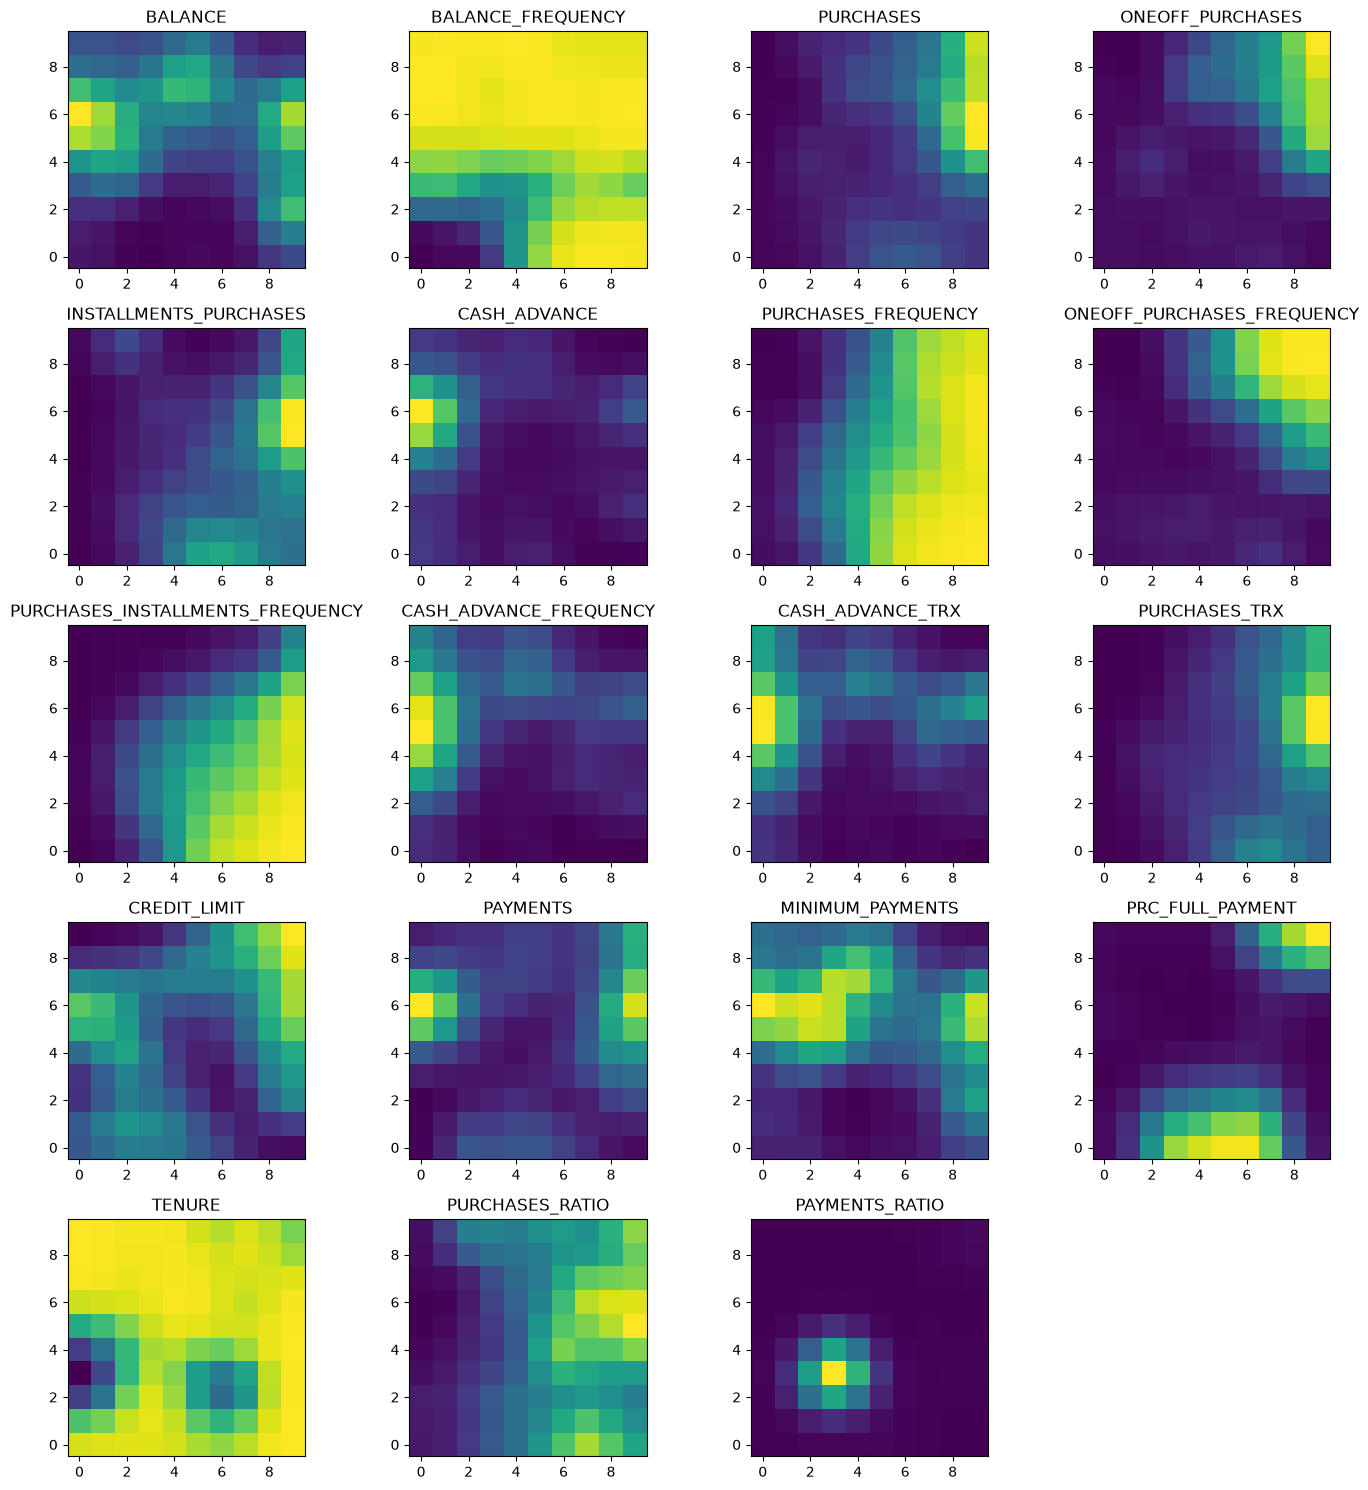

In [27]:
# U-Matrix
plt.imshow(som.distance_map().T, origin="lower", cmap="bone_r")
plt.colorbar()
plt.title("U-Matrix")
plt.show()

# Component planes
weights = som.get_weights()
features = data.columns

fig, axes = plt.subplots(int(np.ceil(len(features)/4)), 4, figsize=(14, 3 * int(np.ceil(len(features)/4))))
axes = np.array(axes).reshape(-1)

for i, feature in enumerate(features):
    axes[i].imshow(weights[:, :, i].T, origin="lower", cmap="viridis")
    axes[i].set_title(feature)

for ax in axes[len(features):]:
    ax.remove()

plt.tight_layout()
plt.show()


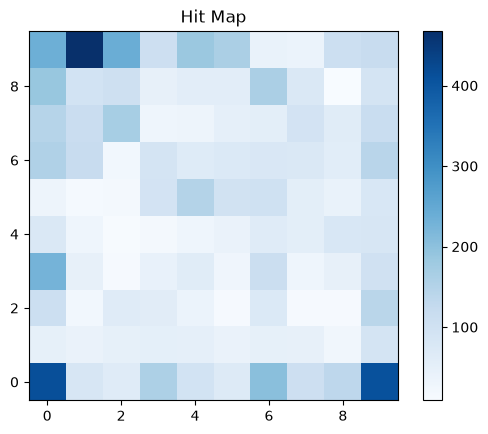

In [28]:
# Find BMU for every customer and make hit map
bmus = np.array([som.winner(row) for row in X])
hit_map = np.zeros((10, 10))

for x, y in bmus:
    hit_map[x, y] += 1

plt.imshow(hit_map.T, origin="lower", cmap="Blues")
plt.colorbar()
plt.title("Hit Map")
plt.show()


## 6. Customer clustering

Selected clusters: 5


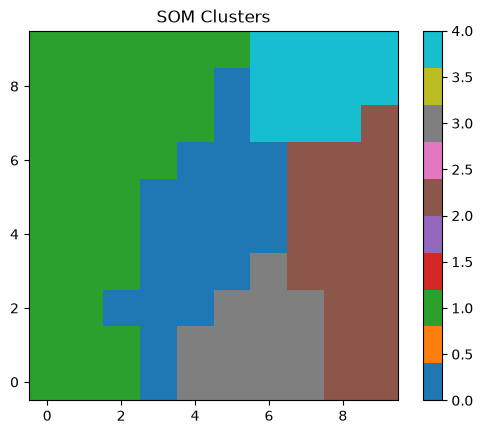

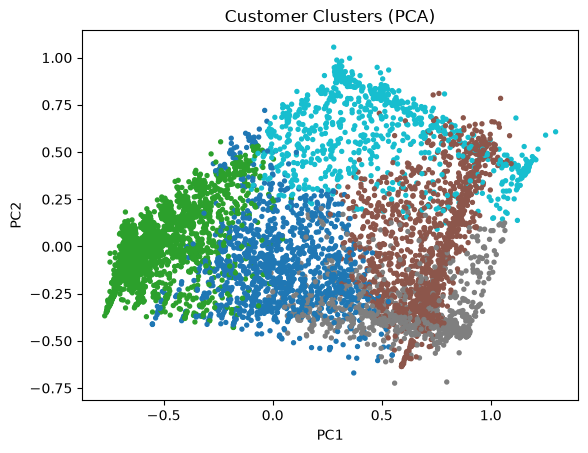

In [29]:
# Apply K-means to SOM weights (3 to 5 clusters)
weights = som.get_weights()
weight_data = weights.reshape(-1, X.shape[1])

scores = {}
for k in range(3, 6):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    scores[k] = km.fit(weight_data).inertia_

best_k = min(scores, key=scores.get)
print("Selected clusters:", best_k)

km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
map_clusters = km.fit_predict(weight_data).reshape(10, 10)

# Assign each customer to the cluster of its BMU
clusters = np.array([map_clusters[x, y] for x, y in bmus])

plt.imshow(map_clusters.T, origin="lower", cmap="tab10")
plt.colorbar()
plt.title("SOM Clusters")
plt.show()

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap="tab10", s=8)
plt.title("Customer Clusters (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


## 7. Segment profiling and ANOVA

In [30]:
# Add cluster numbers to customer data
result = data.copy()
result["CUST_ID"] = np.array(customer_id)
result["CLUSTER"] = clusters

# Cluster sizes and average values
print(result["CLUSTER"].value_counts().sort_index())
cluster_means = result.groupby("CLUSTER")[data.columns].mean()
display(cluster_means)


CLUSTER
0    1415
1    4048
2    1773
3     864
4     850
Name: count, dtype: int64


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,PURCHASES_RATIO,PAYMENTS_RATIO
CLUSTER,,,,,,,,,,,,,,,,,,,
0,1253.505968,0.805450,699.854403,315.154049,385.262961,593.503411,0.522726,0.116215,0.411245,0.088470,2.253004,9.860777,4087.755506,1326.181669,774.121998,0.166719,11.814841,0.226390,14.095529
1,1807.193630,0.841973,247.056932,226.096356,21.125114,1477.884776,0.103645,0.080382,0.022974,0.202668,4.788785,2.038043,4138.785708,1484.416408,861.266080,0.034096,11.382905,0.086609,6.697433
2,2059.456202,0.957265,2073.189165,998.613339,1074.860942,790.441342,0.964472,0.296732,0.918540,0.100490,2.661591,36.741117,5185.363790,2364.984296,1317.753828,0.056077,11.909193,0.468948,10.689307
3,231.984934,0.904034,982.207338,184.644201,798.395289,185.638588,0.875646,0.076880,0.802189,0.032406,0.584491,17.192130,3558.914668,1078.041508,230.423080,0.655847,10.629630,0.373585,6.565279
4,1248.197789,0.970866,2898.719165,2365.952235,532.766929,443.255667,0.897482,0.858394,0.311930,0.067986,1.505882,34.651765,6373.290909,2943.091498,523.135013,0.394991,11.747059,0.617872,11.057169


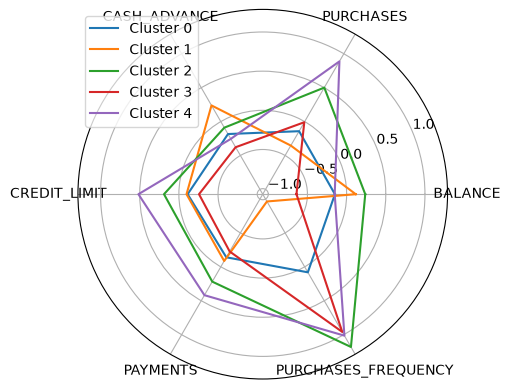

In [31]:
# Radar chart for selected features
radar_features = [f for f in ["BALANCE", "PURCHASES", "CASH_ADVANCE",
                  "CREDIT_LIMIT", "PAYMENTS", "PURCHASES_FREQUENCY"]
                  if f in data.columns]

if len(radar_features) >= 3:
    means = cluster_means[radar_features]
    means = (means - data[radar_features].mean()) / data[radar_features].std()
    angles = np.linspace(0, 2*np.pi, len(radar_features), endpoint=False)
    angles = np.append(angles, angles[0])

    ax = plt.subplot(111, polar=True)
    for c in means.index:
        values = np.append(means.loc[c].values, means.loc[c].values[0])
        ax.plot(angles, values, label=f"Cluster {c}")
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(radar_features)
    ax.legend()
    plt.show()


In [32]:
# ANOVA test for each feature
for feature in data.columns:
    groups = [result[result["CLUSTER"] == c][feature]
              for c in sorted(result["CLUSTER"].unique())]
    f_value, p_value = f_oneway(*groups)
    print(feature, "F =", round(f_value, 3), "p =", round(p_value, 5))


BALANCE F = 149.439 p = 0.0
BALANCE_FREQUENCY F = 150.921 p = 0.0
PURCHASES F = 505.223 p = 0.0
ONEOFF_PURCHASES F = 402.605 p = 0.0
INSTALLMENTS_PURCHASES F = 595.895 p = 0.0
CASH_ADVANCE F = 124.052 p = 0.0
PURCHASES_FREQUENCY F = 17053.337 p = 0.0
ONEOFF_PURCHASES_FREQUENCY F = 3152.204 p = 0.0
PURCHASES_INSTALLMENTS_FREQUENCY F = 11734.878 p = 0.0
CASH_ADVANCE_FREQUENCY F = 254.516 p = 0.0
CASH_ADVANCE_TRX F = 114.666 p = 0.0
PURCHASES_TRX F = 1158.644 p = 0.0
CREDIT_LIMIT F = 105.735 p = 0.0
PAYMENTS F = 86.968 p = 0.0
MINIMUM_PAYMENTS F = 38.243 p = 0.0
PRC_FULL_PAYMENT F = 1809.04 p = 0.0
TENURE F = 180.371 p = 0.0
PURCHASES_RATIO F = 517.477 p = 0.0
PAYMENTS_RATIO F = 1.288 p = 0.27213


## 8. Business insights

In [33]:
# Check average customer behaviour in each cluster
for c in sorted(result["CLUSTER"].unique()):
    group = result[result["CLUSTER"] == c]
    print("\nCluster:", c)
    print("Customers:", len(group))
    print(group[data.columns].mean().round(2))

print("\nPossible business actions:")
print("High purchase customers: loyalty rewards and premium offers.")
print("Frequent customers: recommend related products.")
print("Low purchase customers: send re-engagement offers.")
print("Cash advance customers: offer suitable payment support.")

# Low engagement indicator (not confirmed churn)
if "PURCHASES" in data.columns and "PURCHASES_FREQUENCY" in data.columns:
    low = (result["PURCHASES"] <= result["PURCHASES"].quantile(0.25)) & (
        result["PURCHASES_FREQUENCY"] <= result["PURCHASES_FREQUENCY"].quantile(0.25))
    print("Possible low-engagement customers:", low.sum())



Cluster: 0
Customers: 1415
BALANCE                             1253.51
BALANCE_FREQUENCY                      0.81
PURCHASES                            699.85
ONEOFF_PURCHASES                     315.15
INSTALLMENTS_PURCHASES               385.26
CASH_ADVANCE                         593.50
PURCHASES_FREQUENCY                    0.52
ONEOFF_PURCHASES_FREQUENCY             0.12
PURCHASES_INSTALLMENTS_FREQUENCY       0.41
CASH_ADVANCE_FREQUENCY                 0.09
CASH_ADVANCE_TRX                       2.25
PURCHASES_TRX                          9.86
CREDIT_LIMIT                        4087.76
PAYMENTS                            1326.18
MINIMUM_PAYMENTS                     774.12
PRC_FULL_PAYMENT                       0.17
TENURE                                11.81
PURCHASES_RATIO                        0.23
PAYMENTS_RATIO                        14.10
dtype: float64

Cluster: 1
Customers: 4048
BALANCE                             1807.19
BALANCE_FREQUENCY                      0.84
PURCH

## 9. Save results

In [34]:
# Save customer clusters and segment averages in the same folder
result.to_csv("customer_som_segments.csv", index=False)
cluster_means.to_csv("segment_profile_means.csv")

print("Saved files:")
print("som_trained_model.pkl")
print("som_weights.npy")
print("customer_som_segments.csv")
print("segment_profile_means.csv")


Saved files:
som_trained_model.pkl
som_weights.npy
customer_som_segments.csv
segment_profile_means.csv


**Conclusion:** Use the cluster averages and SOM plots to describe the customer groups. The dataset does not include a churn label, so low engagement is only a possible risk indicator.